# The vibrational front end

This tutorial walks through how `src/vibrations.py` turns a molecule's vibrations into a matrix the selection engine can use, and checks the result against measured frequencies. It takes about 25 minutes and picks up where Tutorial 4 left off. We'll use water throughout, since its whole calculation takes a couple of minutes.

If you open this outside the repo, or on Colab, the first cell downloads the code from GitHub. The guess cells work the same way as before: replace `None` with your answer, run that cell, then run the one after it to check.

In [1]:
import importlib.util
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np

ROOT = ""  # if your COBWEB folder is somewhere else, set this to its path
if not len(ROOT):
    ROOT = "../.." if os.path.isfile("../../src/vibrations.py") else "COBWEB"
if not os.path.isfile(f"{ROOT}/src/vibrations.py"):
    !git clone -q https://github.com/DChristensen12/COBWEB.git {ROOT}
for package in ["pyscf", "geometric"]:
    if importlib.util.find_spec(package) is None:
        %pip install -q {package}

from scipy.linalg import eigh

sys.path.append(f"{ROOT}/src")
from utils import epstein_nesbet_order, ground_state, reference_config, subspace_energy
from vibrations import AMU_TO_ME, EXPERIMENT, HARTREE_TO_CM, equilibrium
from vibrations import fundamentals, normal_modes, quartic_force_field, run_scf
from vibrations import vci_hamiltonian

plt.style.use(f"{ROOT}/figures.mplstyle")
os.makedirs(f"{ROOT}/figures/week5", exist_ok=True)


def check(guess, answer, tol=0):
    if guess is None:
        print("Put your guess in first, then run this cell again")
        return
    right = guess == answer if isinstance(answer, str) else abs(guess - answer) <= tol
    print(f"Correct, it's {answer}" if right else f"Not quite. You said {guess}, it's {answer}")

## Normal modes

A molecule with N atoms has 3N - 6 ways to vibrate (3N - 5 if it is linear), called normal modes. In each one, every atom moves back and forth at the same frequency. In the harmonic picture each mode is an independent spring, and its frequency is all there is to know.

How many normal modes does water have?

In [2]:
my_guess = None

We'll optimize the geometry, compute the harmonic frequencies and check.

In [3]:
mol = equilibrium("water")
mf = run_scf(mol)
omega, modes, mass = normal_modes(mol, mf)
check(my_guess, len(omega))

names = ["bend", "symmetric stretch", "antisymmetric stretch"]
for name, w, m in zip(names, omega * HARTREE_TO_CM, EXPERIMENT["water"]):
    print(f"{name:>22}: harmonic {w:6.0f}, measured {m:6.0f} cm-1")

Put your guess in first, then run this cell again
                  bend: harmonic   1604, measured   1595 cm-1
     symmetric stretch: harmonic   3814, measured   3657 cm-1
 antisymmetric stretch: harmonic   3934, measured   3756 cm-1


Notice that the two stretches come out 150 to 180 cm-1 too high. Real bonds get softer as they stretch, and a spring never does. The bend lands within 10 cm-1, but that turns out to be luck, as we'll see further down.

## Beyond springs

To do better we keep more terms in the potential energy. Written in each mode's dimensionless coordinate $q_i$, it becomes

$$V = \sum_i \frac{\omega_i}{2} q_i^2 + \frac{1}{6}\sum_{ijk} \phi_{ijk}\, q_i q_j q_k + \frac{1}{24}\sum_{ijkl} \phi_{ijkl}\, q_i q_j q_k q_l$$

The cubic and quartic force constants, the $\phi$, are what the harmonic picture leaves out. They make a bond easier to stretch than to compress, and they let one mode's motion change another's. We call the whole expansion a quartic force field.

We get the constants from Hessians, the matrix of second derivatives PySCF already computes. We nudge the molecule a little along one mode and compute the Hessian on both sides. Their difference gives the cubic constants, and their sum gives the quartic ones. That takes one Hessian at the minimum plus two for every mode.

How many Hessians does water need?

In [4]:
my_guess = None

Now we'll compute the force field. This is the slow step, about a minute for water.

In [5]:
start = time.time()
w, phi3, phi4 = quartic_force_field("water")
check(my_guess, 2 * len(w) + 1)
print(f"Force field took {time.time() - start:.0f} s")

Put your guess in first, then run this cell again
Force field took 132 s


For formic acid, with 9 modes, the same step takes 19 Hessians, about 20 minutes on a single core. That's why `make vibrations` saves each force field to `results/forcefields` and only recomputes it when the file is missing.

## Checking the force field

Before we trust the constants, we'll compare the force field against real energies. We'll step along the symmetric stretch, compute the DFT energy at each point, and draw both the harmonic and quartic curves over them.

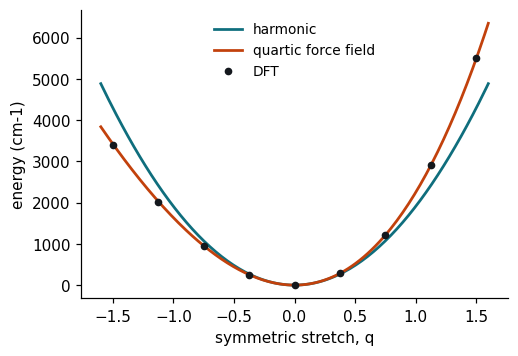

In [6]:
k = 1  # the symmetric stretch
qs = np.linspace(-1.5, 1.5, 9)
dft = []
for q in qs:
    dx = (modes[k] / np.sqrt(np.repeat(mass, 3) * AMU_TO_ME)).reshape(-1, 3)
    displaced = mol.copy()
    displaced.set_geom_(mol.atom_coords() + dx * q / np.sqrt(omega[k]), unit="Bohr")
    dft.append((run_scf(displaced).e_tot - mf.e_tot) * HARTREE_TO_CM)

x = np.linspace(-1.6, 1.6, 200)
harmonic = 0.5 * w[k] * x**2
quartic = harmonic + phi3[k, k, k] * x**3 / 6 + phi4[k, k, k, k] * x**4 / 24

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(x, harmonic, c="#0f6e7d", label="harmonic")
ax.plot(x, quartic, c="#c2410c", label="quartic force field")
ax.plot(qs, dft, "o", c="#14181d", label="DFT")
ax.set_xlabel("symmetric stretch, q")
ax.set_ylabel("energy (cm-1)")
ax.legend()
fig.savefig(f"{ROOT}/figures/week5/stretch_scan.svg")
plt.show()

Notice that the quartic curve sits on the DFT points, while the harmonic curve misses on both sides. Where the bonds stretch, the real energy rises more slowly than the spring's, and where they compress it rises faster. That lopsidedness is the cubic term at work.

## The vibrational Hamiltonian

For the Hamiltonian we need a basis. We take a harmonic oscillator state for each mode and build every product of them with at most `max_quanta` quanta in total. With 3 modes and 6 quanta, how many states is that?

In [7]:
my_guess = None

We'll build the matrix and check.

In [8]:
H, labels = vci_hamiltonian(w, phi3, phi4, 6)
check(my_guess, len(labels))
print(f"H has a shape of {H.shape}, symmetric: {np.allclose(H, H.T)}")

E, C = eigh(H)
print(f"Zero-point energy {E[0]:.1f} cm-1, against {0.5 * w.sum():.1f} for the springs")
print(f"The ground state puts {C[0, 0] ** 2:.3f} of its weight on the all-zero state")

Put your guess in first, then run this cell again
H has a shape of (84, 84), symmetric: True
Zero-point energy 4618.7 cm-1, against 4676.2 for the springs
The ground state puts 0.976 of its weight on the all-zero state


Each row is labeled by how many quanta sit in each mode, just like the configurations in Tutorial 2. Notice the ground state sits almost entirely on the all-zero state. Water's vibrations are only mildly anharmonic.

## Fundamentals against experiment

A fundamental is the energy to put one quantum into one mode. For each mode we find the eigenstate that looks most like one quantum there, and subtract the zero-point energy.

The harmonic bend was already within 10 cm-1 of the measured value. Once we add anharmonicity, does it move closer or further away? Answer "closer" or "further".

In [9]:
my_guess = None

In [10]:
nu = fundamentals(E, C, labels)
for name, harm, fund, m in zip(names, w, nu, EXPERIMENT["water"]):
    print(f"{name:>22}: harmonic {harm:6.0f}, VCI {fund:6.0f}, measured {m:6.0f}, error {fund - m:+4.0f} cm-1")

bend_before, bend_after = abs(w[0] - EXPERIMENT["water"][0]), abs(nu[0] - EXPERIMENT["water"][0])
check(my_guess, "closer" if bend_after < bend_before else "further")

                  bend: harmonic   1604, VCI   1528, measured   1595, error  -67 cm-1
     symmetric stretch: harmonic   3814, VCI   3673, measured   3657, error  +16 cm-1
 antisymmetric stretch: harmonic   3934, VCI   3777, measured   3756, error  +21 cm-1
Put your guess in first, then run this cell again


The two stretches now land within about 20 cm-1, down from 150 to 180. The bend goes the wrong way and ends up about 67 cm-1 low.

The harmonic bend was right for the wrong reasons, since B3LYP's error and the missing anharmonicity happened to cancel. Our force field also uses straight-line normal coordinates, which describe bending and twisting less well than stretching, and it leaves out the coupling between vibration and rotation. Those are limits of the model, not the code. The tests check the code against PySCF and against an exact grid calculation.

## How big a basis is enough

Six quanta was a choice. We'll rebuild the matrix with more and more quanta and watch the fundamentals settle.

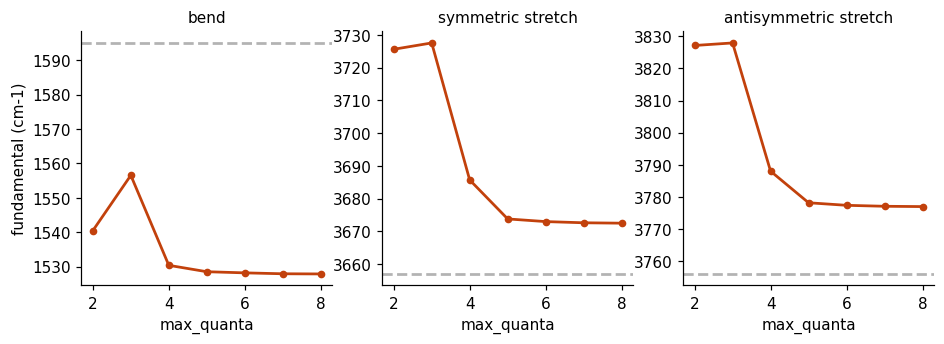

Largest change from 6 to 7 quanta: 0.36 cm-1


In [11]:
sizes = range(2, 9)
history = []
for max_quanta in sizes:
    Hq, lq = vci_hamiltonian(w, phi3, phi4, max_quanta)
    Eq, Cq = eigh(Hq)
    history.append(fundamentals(Eq, Cq, lq))
history = np.array(history)  # max_quanta x modes

fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharex=True)
for ax, i, name in zip(axes, range(3), names):
    ax.plot(list(sizes), history[:, i], "o-", c="#c2410c")
    ax.axhline(EXPERIMENT["water"][i], c=(.7, .7, .7), ls="--")  # measured
    ax.set_title(name)
    ax.set_xlabel("max_quanta")
axes[0].set_ylabel("fundamental (cm-1)")
fig.savefig(f"{ROOT}/figures/week5/convergence.svg")
plt.show()
print(f"Largest change from 6 to 7 quanta: {np.max(np.abs(history[5] - history[4])):.2f} cm-1")

Notice that the fundamentals settle by 6 quanta. The dashed lines are the measured values, and the gap that remains is the model's, not the basis's.

Not every molecule settles this nicely. When a quartic force field has a large negative coupling between two modes, the potential can turn downward far from equilibrium, and a big enough basis reaches into that region.

## Handing it to the selection engine

The matrix has the same form as every other system in the project, a matrix plus a label for each row. So the selection engine works on it unchanged.

How many of the 84 configurations does perturbation theory need to get the zero-point energy within 1 cm-1?

In [12]:
my_guess = None

Put your guess in first, then run this cell again


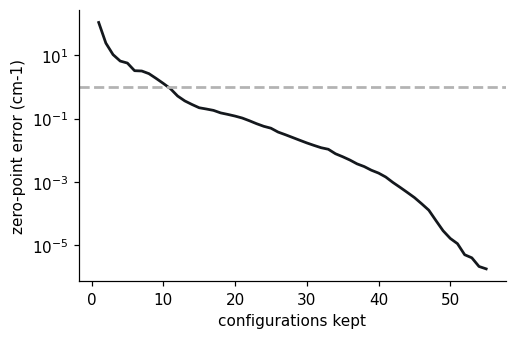

In [13]:
E0, c0 = ground_state(H)
order = epstein_nesbet_order(H, [reference_config(H)], len(H))
k_all = np.arange(1, len(H) + 1)
err = np.array([subspace_energy(H, order[:k]) - E0 for k in k_all])
check(my_guess, int(k_all[np.argmax(err < 1)]), tol=3)

fig, ax = plt.subplots(figsize=(5, 3.2))
shown = err > 1e-6  # stop the line once the error is effectively zero
ax.semilogy(k_all[shown], err[shown], c="#14181d")
ax.axhline(1, c=(.7, .7, .7), ls="--")  # 1 cm-1
ax.set_xlabel("configurations kept")
ax.set_ylabel("zero-point error (cm-1)")
fig.savefig(f"{ROOT}/figures/week5/selection.svg")
plt.show()

## Where this leaves us

Water now runs all the way from a geometry to a Hamiltonian, fundamentals within reach of experiment, and a matrix the selection engine can use. Formic acid, the molecule whose IR spectrum we're after, is this week's open spot, along with a basis convergence helper and one test. Once it's in, `make vibrations` computes its force field once and saves it, and the next tutorial runs the full comparison on both molecules.

## Things to try

Each of these is a one-line change, then rerun the cells below it.

In the Hamiltonian cell, change the 6 to 3. How far do the fundamentals move?

In the force field cell, call `quartic_force_field("water", step=0.05)`, twice the default step. Do the fundamentals change by more than 1 cm-1?

In the last cell, change `err < 1` to `err < 0.1`. How many configurations does perturbation theory need now?